In [15]:
#247040
#Meshal Mahnoor

GitHubLink: [ViT](https://)

Import Libraries: Main libraray is PyTorch

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
#torchvision is PyTorch’s vision toolkit. transforms = image preprocessing, datasets = ready dataset loaders.
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
# Hugging Face Transformers. ViTForImageClassification is a pretrained Vision
#Transformer that is built on PyTorch, so it behaves like any torch.nn.Module.
from transformers import ViTForImageClassification
# functional API of PyTorch; we need F.interpolate to enlarge the 14x14 attention map.
import torch.nn.functional as F
#torch is the PyTorch core library (tensors, GPU support, automatic computation).
import torch

Lets see if CUDA is available otherwise fall back to CPU

In [17]:
#torch.device chooses where tensors and the model live. torch.cuda.is_available()
#returns True when a GPU is present. Both the model and the input images must be on the
#same device.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


Loading a ViT model:

In [18]:
# "vit-base-patch16-224" = Base ViT, 16x16 patches, 224x224 input. 224/16 = 14, so an
#image becomes 14 x 14 = 196 patch tokens, plus 1 special [CLS] token = 197 tokens in
#total.
model_name = "google/vit-base-patch16-224"
model = ViTForImageClassification.from_pretrained(
model_name,# "eager" forces the plain attention code. The faster fused attention kernels do
#not return the attention weights, so "eager" is required if we want to visualise
#attention later.
attn_implementation="eager"
).to(device)
# eval() switches the model to inference mode (turns off dropout) so pred are stable.
model.eval()
# Enable attention and hidden-state outputs
# these flags ask the model to also return the attention metrices and hidden states of
#every layer.
model.vit.config.output_attentions = True
model.vit.config.output_hidden_states = True
print("ViT-B/16 classifier loaded")
config = model.config
print("Model:", model_name)
print("Number of encoder blocks:", config.num_hidden_layers)
print("Attention heads:", config.num_attention_heads)
print("Hidden size:", config.hidden_size)
print("MLP size:", config.intermediate_size)
print("Image size:", config.image_size)
print("Patch size:", config.patch_size)
print("Number of output classes:", config.num_labels)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViT-B/16 classifier loaded
Model: google/vit-base-patch16-224
Number of encoder blocks: 12
Attention heads: 12
Hidden size: 768
MLP size: 3072
Image size: 224
Patch size: 16
Number of output classes: 1000


Dataset and preprocessing: Dataset will be uploaded to drive and taken from there.

In [19]:
DATA_ROOT = "/content/drive/MyDrive/CV Lab + Class/data2"
transform = transforms.Compose([
# transforms.Compose chains the preprocessing steps in order: Resize to 224x224
#(the ViT input size), ToTensor converts the image to a tensor with values 0 to 1, and
#Normalize subtracts the mean and divides by the std for each RGB channel.
transforms.Resize((224, 224)),
transforms.ToTensor(),
transforms.Normalize(
mean=[0.485, 0.456, 0.406],
std=[0.229, 0.224, 0.225]
)
])
# ImageFolder treats each sub-folder as one class and the folder name as the label.
# Here the folder name itself (e.g. 00155) is the ImageNet index, so it is the true
#ground truth.
dataset = datasets.ImageFolder(
root=DATA_ROOT,
transform=transform
)
print(f"\nDataset size: {len(dataset)}")
print(f"Number of folders: {len(dataset.classes)}")
print(f"Folders: {dataset.classes}")


Dataset size: 41
Number of folders: 34
Folders: ['00001', '00012', '00013', '00014', '00015', '00016', '00017', '00018', '00019', '00020', '00071', '00146', '00150', '00151', '00152', '00153', '00154', '00155', '00156', '00157', '00158', '00159', '00160', '00185', '00186', '00284', '00438', '00444', '00463', '00491', '00492', '00494', '00587', '00719']


Creating Class labels:

In [20]:
# DataLoader wraps the dataset and delivers images in batches. batch_size=1 processes
#one image at a time, and shuffle=False keeps the original order so that position idx
#always matches dataset.samples[idx].
dataloader = DataLoader(
dataset,
batch_size=1,
shuffle=False,
num_workers=0
)
# id2label is a dictionary {0: "tench", 1: "goldfish", ...} that turns a class number into a readable name.
id2label = model.config.id2label

Making inference

In [21]:
results = []
model.eval()
# torch.no_grad() turns off gradient tracking. We are only predicting, not training, so this saves memory and time.
with torch.no_grad():
 for idx, (images, labels) in enumerate(dataloader):
# .to(device) moves the image tensor onto the GPU so it is on the same deviceas the model.
  images = images.to(device)
# Original image information
  img_path, true_label_idx = dataset.samples[idx]
  folder_name = os.path.basename(os.path.dirname(img_path))
  file_name = os.path.basename(img_path)
# the forward pass. The result holds logits (raw scores for 1000 classes), plus attentions and hidden_states
  outputs = model(
pixel_values=images,
output_attentions=True,
output_hidden_states=True
)
  logits = outputs.logits
# softmax converts raw logits into probabilities that sum to 1 (this is the "confidence").
  probs = torch.softmax(logits, dim=-1)
# argmax gives the index of the highest probability (Top-1). .item() converts a one-value tensor to a normal Python number.
  pred_class_idx = torch.argmax(probs, dim=-1).item()
  confidence = probs[0, pred_class_idx].item()
  pred_label = id2label[pred_class_idx]
# torch.topk returns the k largest probabilities and their class indices (here k=5 for the Top-5 list).
  top5_probs, top5_indices = torch.topk(
probs,
k=5,
dim=-1
)
  top5_predictions = []
  for rank in range(5):
    class_idx = top5_indices[0, rank].item()
    class_prob = top5_probs[0, rank].item()
    class_label = id2label[class_idx]
    top5_predictions.append({
"rank": rank + 1,
"class_index": class_idx,

"label": class_label,
"confidence": class_prob
})
# Store all results
    results.append({
"dataset_index": idx,
"image_path": img_path,
"file_name": file_name,
"folder_name": folder_name,
"true_label_idx": true_label_idx,
"pred_class_idx": pred_class_idx,
"pred_label": pred_label,
"confidence": confidence,
"top5": top5_predictions
})
    if (idx + 1) % 10 == 0 or (idx + 1) == len(dataset):
     print(f"Processed {idx + 1}/{len(dataset)} images")

print("\nInference completed.")
print(f"Total images processed: {len(results)}")

Processed 10/41 images
Processed 10/41 images
Processed 10/41 images
Processed 10/41 images
Processed 10/41 images
Processed 20/41 images
Processed 20/41 images
Processed 20/41 images
Processed 20/41 images
Processed 20/41 images
Processed 30/41 images
Processed 30/41 images
Processed 30/41 images
Processed 30/41 images
Processed 30/41 images
Processed 40/41 images
Processed 40/41 images
Processed 40/41 images
Processed 40/41 images
Processed 40/41 images
Processed 41/41 images
Processed 41/41 images
Processed 41/41 images
Processed 41/41 images
Processed 41/41 images

Inference completed.
Total images processed: 205


Display Predictions:


DATASET INDEX: 0
Image file: 4688179944691877.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00001/4688179944691877.jpg
Folder name (GT): 00001
Dataset label index: 0

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 1
Predicted label: goldfish, Carassius auratus
Confidence: 0.9995

TOP-5 PREDICTIONS
--------------------------------------------------
1. goldfish, Carassius auratus (Class index: 1, Confidence: 0.9995)
2. tench, Tinca tinca (Class index: 0, Confidence: 0.0002)
3. barracouta, snoek (Class index: 389, Confidence: 0.0000)
4. axolotl, mud puppy, Ambystoma mexicanum (Class index: 29, Confidence: 0.0000)
5. anemone fish (Class index: 393, Confidence: 0.0000)


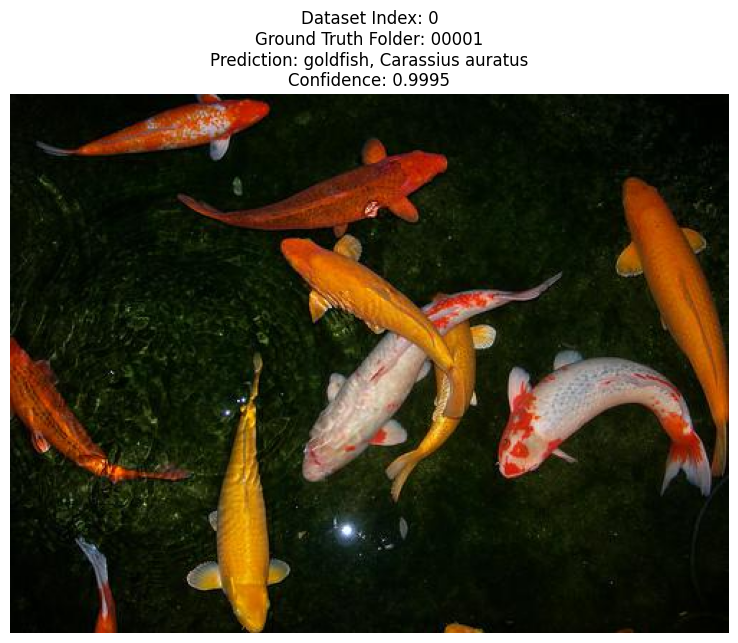


DATASET INDEX: 1
Image file: 352807011784034.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00012/352807011784034.jpg
Folder name (GT): 00012
Dataset label index: 1

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 12
Predicted label: house finch, linnet, Carpodacus mexicanus
Confidence: 0.9911

TOP-5 PREDICTIONS
--------------------------------------------------
1. house finch, linnet, Carpodacus mexicanus (Class index: 12, Confidence: 0.9911)
2. brambling, Fringilla montifringilla (Class index: 10, Confidence: 0.0041)
3. indigo bunting, indigo finch, indigo bird, Passerina cyanea (Class index: 14, Confidence: 0.0015)
4. goldfinch, Carduelis carduelis (Class index: 11, Confidence: 0.0007)
5. junco, snowbird (Class index: 13, Confidence: 0.0005)


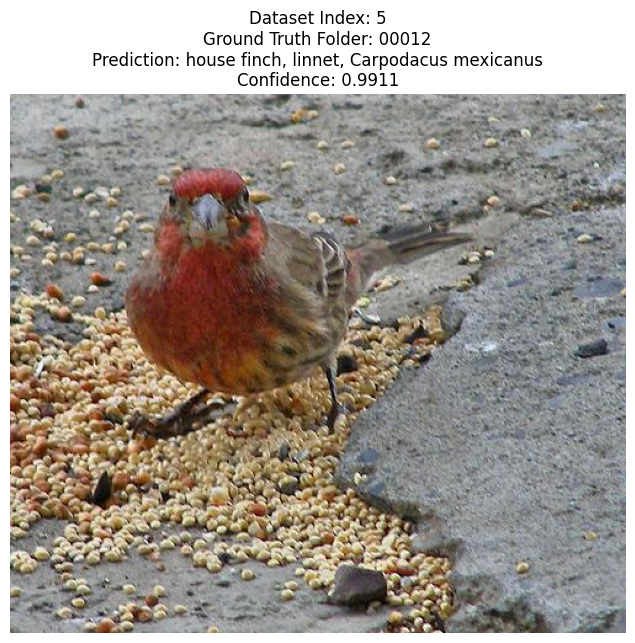


DATASET INDEX: 2
Image file: 606843467581765.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00013/606843467581765.jpg
Folder name (GT): 00013
Dataset label index: 2

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 13
Predicted label: junco, snowbird
Confidence: 0.9833

TOP-5 PREDICTIONS
--------------------------------------------------
1. junco, snowbird (Class index: 13, Confidence: 0.9833)
2. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.0112)
3. chickadee (Class index: 19, Confidence: 0.0007)
4. magpie (Class index: 18, Confidence: 0.0007)
5. jay (Class index: 17, Confidence: 0.0007)


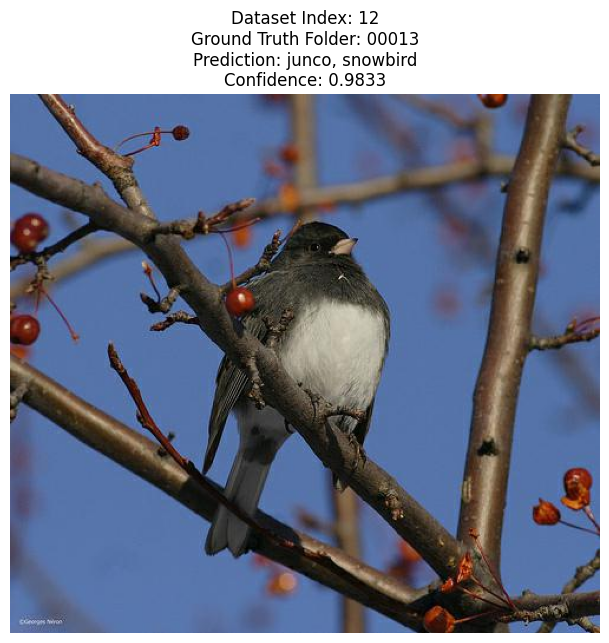


DATASET INDEX: 4
Image file: 7374881593269804.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00015/7374881593269804.jpg
Folder name (GT): 00015
Dataset label index: 4

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 15
Predicted label: robin, American robin, Turdus migratorius
Confidence: 0.9985

TOP-5 PREDICTIONS
--------------------------------------------------
1. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.9985)
2. worm fence, snake fence, snake-rail fence, Virginia fence (Class index: 912, Confidence: 0.0002)
3. grey fox, gray fox, Urocyon cinereoargenteus (Class index: 280, Confidence: 0.0002)
4. house finch, linnet, Carpodacus mexicanus (Class index: 12, Confidence: 0.0001)
5. brambling, Fringilla montifringilla (Class index: 10, Confidence: 0.0001)


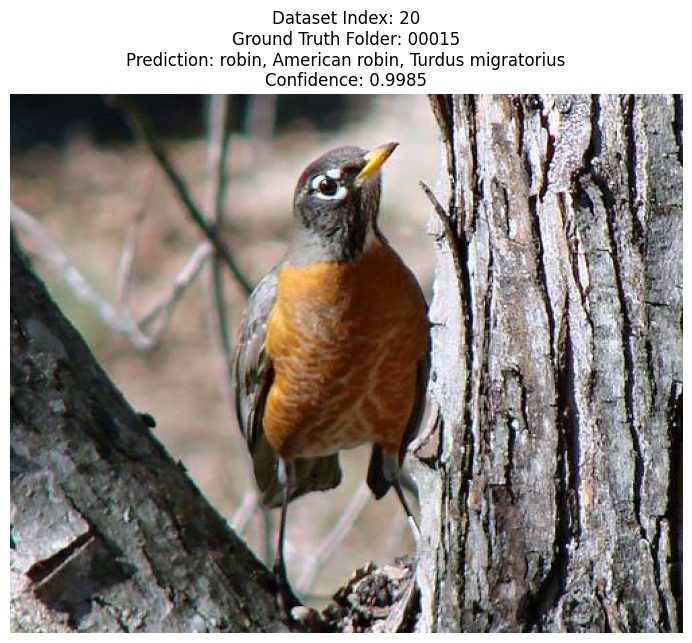

In [31]:
# a list of dataset positions that we inspect in detail; the same list is reused forb the attention rollout later.
SELECTED_INDICES = [0, 5, 12, 20]
# Display selected predictions with original images
for selected_idx in SELECTED_INDICES:
 if selected_idx < 0 or selected_idx >= len(results):
  print(f"Invalid dataset index: {selected_idx}")
  continue
 result = results[selected_idx]
 print("\n" + "=" * 75)

 print(f"DATASET INDEX: {result['dataset_index']}")
 print("=" * 75)
 print(f"Image file: {result['file_name']}")
 print(f"Full path: {result['image_path']}")
 print(f"Folder name (GT): {result['folder_name']}")
 print(f"Dataset label index: {result['true_label_idx']}")

 print("\nTOP-1 PREDICTION")
 print("-" * 50)

 print(f"Predicted ImageNet class index: {result['pred_class_idx']}")
 print(f"Predicted label: {result['pred_label']}")
 print(f"Confidence: {result['confidence']:.4f}")

 print("\nTOP-5 PREDICTIONS")
 print("-" * 50)
 for prediction in result["top5"]:
  print(
f"{prediction['rank']}. "
f"{prediction['label']} "
f"(Class index: {prediction['class_index']}, "
f"Confidence: {prediction['confidence']:.4f})"
)
# PIL.Image.open loads the original full-size image (before the 224x224 resizing) so it can be displayed clearly.
 img = Image.open(result["image_path"]).convert("RGB")
# Display image alongside prediction information
 plt.figure(figsize=(13, 7))
 plt.imshow(img)
 plt.title(
f"Dataset Index: {selected_idx}\n"
f"Ground Truth Folder: {result['folder_name']}\n"
f"Prediction: {result['pred_label']}\n"
f"Confidence: {result['confidence']:.4f}",
fontsize=12
)
 plt.axis("off")
 plt.show()

Extracting the attention maps

In [32]:
# Extract Attention Maps
def get_attention_maps(model, image_tensor):
 with torch.no_grad():
# output_attentions=True makes the model return its self-attention matrices.
  outputs = model(
pixel_values=image_tensor,
output_attentions=True
)
# attentions is a tuple of 12 tensors (one per encoder block). Each has shape (1,12, 197, 197) = (batch, heads, tokens, tokens). Entry [i, j] says how much token i
#attends to token j.
 return outputs.attentions

Implementing attention rollout

In [33]:
def attention_rollout(attentions, discard_ratio=0.0):
 num_tokens = attentions[0].shape[-1]
# Attention Rollout starts from the identity matrix and multiplies the attention of
#each layer onto it. This traces how information flows from the input patches to the final layer.
 result = torch.eye(
 num_tokens,
device=attentions[0].device
)
 for attention in attentions:
# Remove batch dimension
  attention = attention.squeeze(0)
# averages the 12 heads into a single 197x197 attention matrix.
  fused = attention.mean(dim=0)
# optional step that sets the weakest attention values to zero to reduce noise. It is off here (discard_ratio=0.0).
  if discard_ratio > 0:
    flat = fused.flatten()
    num_discard = int(
flat.numel() * discard_ratio
)
    if num_discard > 0:
     indices = torch.argsort(flat)[:num_discard]
     flat[indices] = 0

# adding the identity matrix models the residual (skip) connections of the transformer, which pass the original token forward along with the attention output.
  fused = fused + torch.eye(
   num_tokens,
device=fused.device
)
# each row is re-normalised to sum to 1 so it stays a valid attention distribution.
  fused = fused / fused.sum(
dim=-1,
keepdim=True
)
# matrix multiplication (@) chains the layers together, so the final matrix describes attention across the whole network.
  result = fused @ result
# row 0 is the [CLS] token. Taking columns 1 onward gives the importance of the 196 image patches for the classification.
  mask = result[0, 1:]
# the 196 patch values are arranged back into a 14x14 grid matching the patch positions in the image.
  mask = mask.reshape(14, 14)
#bilinear upsampling enlarges the 14x14 grid to 224x224 so it looks like a smooth heatmap.
  mask = F.interpolate(
  mask.unsqueeze(0).unsqueeze(0),
size=(224, 224),
mode="bilinear",
align_corners=False
).squeeze()
 mask = mask.cpu().numpy()
# min-max normalisation scales the map to the range 0 to 1 (1e-8 prevents division by zero).
 mask = (
(mask - mask.min()) /
(mask.max() - mask.min() + 1e-8)
)
 return mask

Attention Visualization Function:

In [34]:
def visualize_attention_rollout(original_image, rollout_map):
# Get original image dimensions
  width, height = original_image.size
# cv2.resize stretches the attention map to the original image width and height so that the overlay is aligned.
  rollout_resized = cv2.resize(
rollout_map,
(width, height),
interpolation=cv2.INTER_CUBIC
)
# np.clip keeps every value inside 0 to 1 (bicubic resizing can overshoot slightly).
  rollout_resized = np.clip(rollout_resized, 0, 1)

# Create visualization
  fig, axes = plt.subplots(
1, 3,
figsize=(18, 6)
)
# 1. Original image
  axes[0].imshow(original_image)
  axes[0].set_title("Original Image", fontsize=13)
  axes[0].axis("off")
# 2. Attention rollout heatmap
  axes[1].imshow(
rollout_resized,
cmap="jet",
vmin=0,
vmax=1,
interpolation="bilinear"
)
  axes[1].set_title(
"Attention Rollout Heatmap",
fontsize=13
)
  axes[1].axis("off")
# 3. Correctly aligned attention overlay
  axes[2].imshow(original_image)
  axes[2].imshow(
rollout_resized,
cmap="jet",
# alpha sets the transparency of the heatmap (0.45) so the original image stays visible underneath.
alpha=0.45,
vmin=0,
vmax=1,
interpolation="bilinear"
)
  axes[2].set_title(
"Attention Rollout Overlay",
fontsize=13
)
  axes[2].axis("off")
  plt.tight_layout()
  plt.show()

Running Attention Rollout on selected image:


ATTENTION ROLLOUT: IMAGE 0
Predicted Class: goldfish, Carassius auratus
Confidence: 0.9995


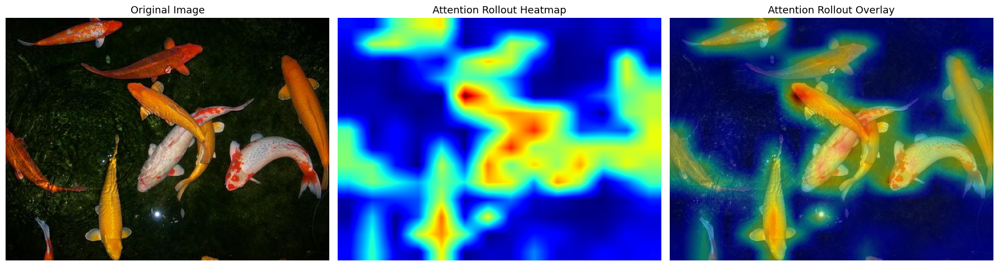


ATTENTION ROLLOUT: IMAGE 5
Predicted Class: house finch, linnet, Carpodacus mexicanus
Confidence: 0.9911


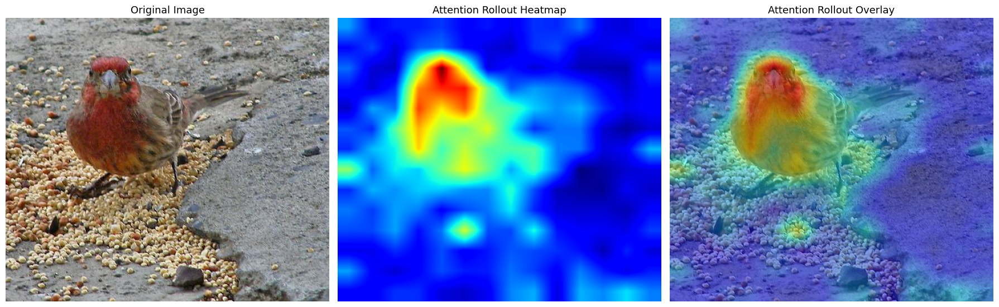


ATTENTION ROLLOUT: IMAGE 12
Predicted Class: junco, snowbird
Confidence: 0.9833


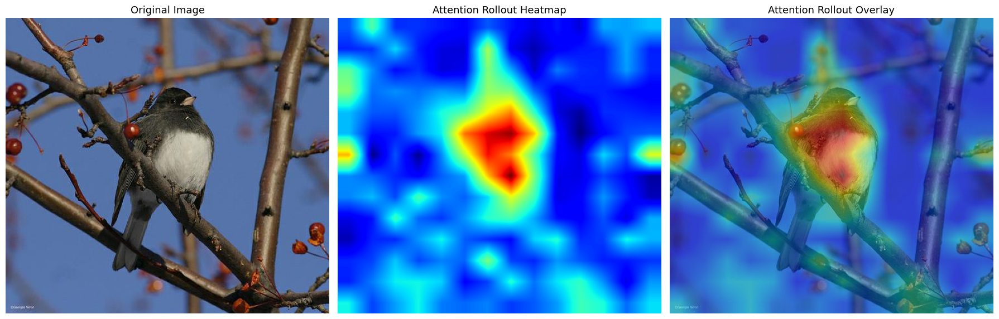


ATTENTION ROLLOUT: IMAGE 20
Predicted Class: robin, American robin, Turdus migratorius
Confidence: 0.9985


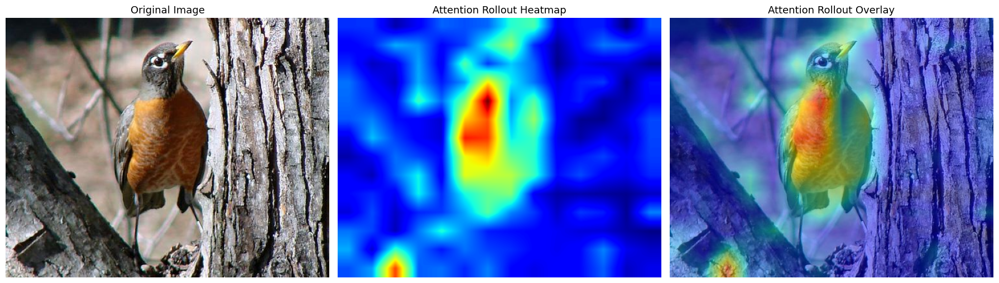

In [35]:
for selected_idx in SELECTED_INDICES:
  if selected_idx < 0 or selected_idx >= len(results):
    continue
  result = results[selected_idx]
  print("\n" + "=" * 70)
  print(f"ATTENTION ROLLOUT: IMAGE {selected_idx}")
  print("=" * 70)

# Load original image
  original_image = Image.open(
result["image_path"]
).convert("RGB")
# NEW: the original image is preprocessed again and .unsqueeze(0) adds the batch dimension, turning (3, 224, 224) into (1, 3, 224, 224) as the model expects.
  image_tensor = transform(
original_image
).unsqueeze(0).to(device)
# Extract attention maps
  attentions = get_attention_maps(
model,
image_tensor
)
# calls the rollout function from Activity 10 on the 12 attention tensors to get one 224x224 map.
  rollout_map = attention_rollout(
attentions,
discard_ratio=0.0
)
  print(f"Predicted Class: {result['pred_label']}")
  print(f"Confidence: {result['confidence']:.4f}")
# Visualize
  visualize_attention_rollout(
original_image,
rollout_map
)

***Observations:***
*alpha value controls the transparency (opacity) of the attention heatmap overlay placed on top of the original input image.*
We are going to change the value of alpha to see the effect on inference.
original alpha value is 0.45.

```
The new alpha value we will test with 0.3(will make it more transparent) and a value of 0.7(will make the heatmap more opaque)
```
Let's test both with different indices of images.


Alpha value 0.3:


DATASET INDEX: 5
Image file: 3294314705554.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00016/3294314705554.jpg
Folder name (GT): 00016
Dataset label index: 5

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 16
Predicted label: bulbul
Confidence: 0.9920

TOP-5 PREDICTIONS
--------------------------------------------------
1. bulbul (Class index: 16, Confidence: 0.9920)
2. jay (Class index: 17, Confidence: 0.0014)
3. house finch, linnet, Carpodacus mexicanus (Class index: 12, Confidence: 0.0009)
4. bee eater (Class index: 92, Confidence: 0.0007)
5. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.0006)


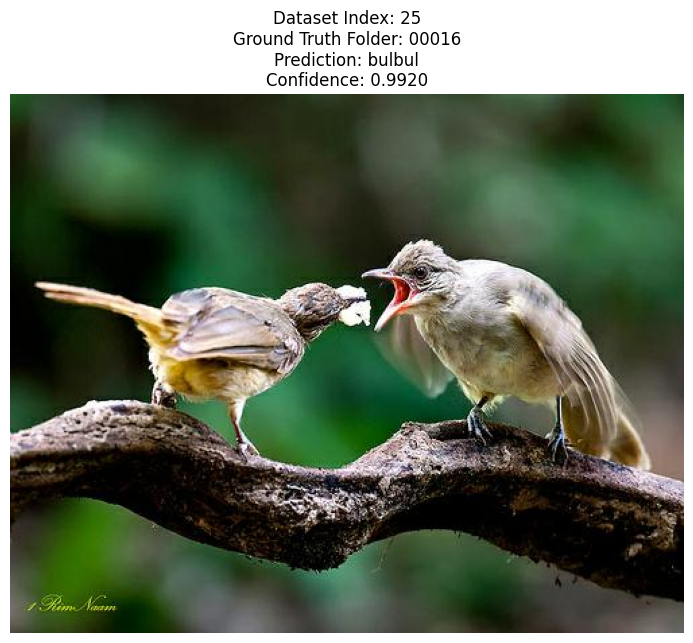


DATASET INDEX: 3
Image file: 613129815376952.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00014/613129815376952.jpg
Folder name (GT): 00014
Dataset label index: 3

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 14
Predicted label: indigo bunting, indigo finch, indigo bird, Passerina cyanea
Confidence: 0.9907

TOP-5 PREDICTIONS
--------------------------------------------------
1. indigo bunting, indigo finch, indigo bird, Passerina cyanea (Class index: 14, Confidence: 0.9907)
2. house finch, linnet, Carpodacus mexicanus (Class index: 12, Confidence: 0.0033)
3. jay (Class index: 17, Confidence: 0.0016)
4. goldfinch, Carduelis carduelis (Class index: 11, Confidence: 0.0011)
5. junco, snowbird (Class index: 13, Confidence: 0.0008)


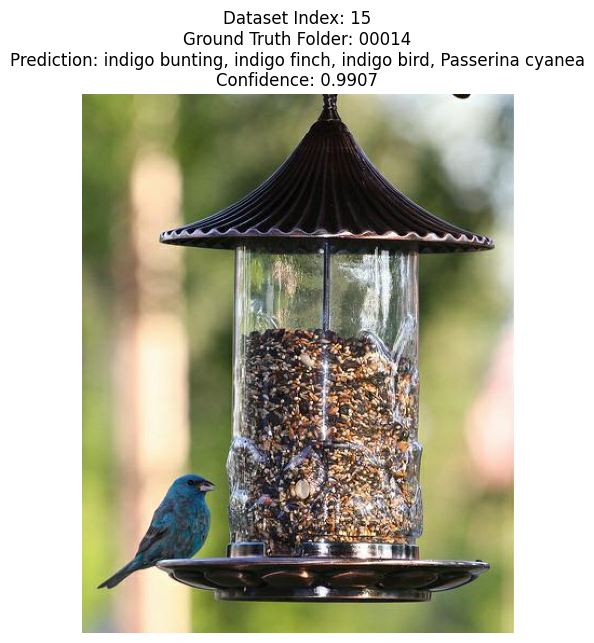


DATASET INDEX: 2
Image file: 606843467581765.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00013/606843467581765.jpg
Folder name (GT): 00013
Dataset label index: 2

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 13
Predicted label: junco, snowbird
Confidence: 0.9833

TOP-5 PREDICTIONS
--------------------------------------------------
1. junco, snowbird (Class index: 13, Confidence: 0.9833)
2. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.0112)
3. chickadee (Class index: 19, Confidence: 0.0007)
4. magpie (Class index: 18, Confidence: 0.0007)
5. jay (Class index: 17, Confidence: 0.0007)


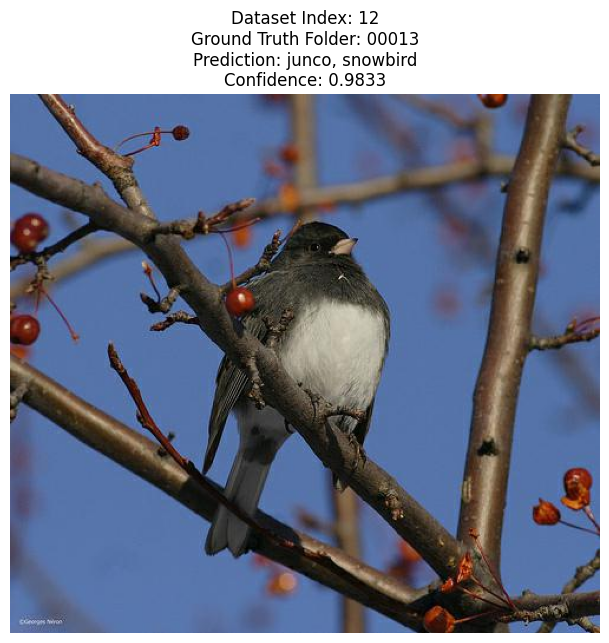


DATASET INDEX: 6
Image file: 368607044767294.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00017/368607044767294.jpg
Folder name (GT): 00017
Dataset label index: 6

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 17
Predicted label: jay
Confidence: 0.9807

TOP-5 PREDICTIONS
--------------------------------------------------
1. jay (Class index: 17, Confidence: 0.9807)
2. magpie (Class index: 18, Confidence: 0.0113)
3. black grouse (Class index: 80, Confidence: 0.0009)
4. indigo bunting, indigo finch, indigo bird, Passerina cyanea (Class index: 14, Confidence: 0.0006)
5. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.0005)


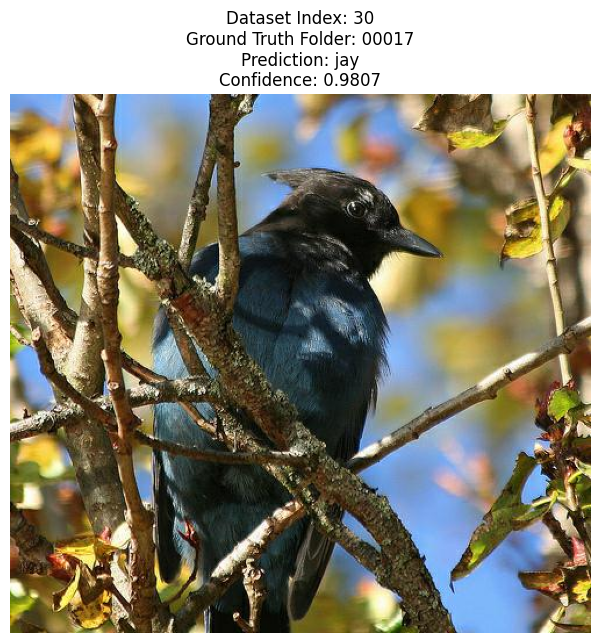

In [37]:
# a list of dataset positions that we inspect in detail; the same list is reused forb the attention rollout later.
SELECTED_INDICES = [25, 15, 12, 30]
# Display selected predictions with original images
for selected_idx in SELECTED_INDICES:
 if selected_idx < 0 or selected_idx >= len(results):
  print(f"Invalid dataset index: {selected_idx}")
  continue
 result = results[selected_idx]
 print("\n" + "=" * 75)

 print(f"DATASET INDEX: {result['dataset_index']}")
 print("=" * 75)
 print(f"Image file: {result['file_name']}")
 print(f"Full path: {result['image_path']}")
 print(f"Folder name (GT): {result['folder_name']}")
 print(f"Dataset label index: {result['true_label_idx']}")

 print("\nTOP-1 PREDICTION")
 print("-" * 50)

 print(f"Predicted ImageNet class index: {result['pred_class_idx']}")
 print(f"Predicted label: {result['pred_label']}")
 print(f"Confidence: {result['confidence']:.4f}")

 print("\nTOP-5 PREDICTIONS")
 print("-" * 50)
 for prediction in result["top5"]:
  print(
f"{prediction['rank']}. "
f"{prediction['label']} "
f"(Class index: {prediction['class_index']}, "
f"Confidence: {prediction['confidence']:.4f})"
)
# PIL.Image.open loads the original full-size image (before the 224x224 resizing) so it can be displayed clearly.
 img = Image.open(result["image_path"]).convert("RGB")
# Display image alongside prediction information
 plt.figure(figsize=(13, 7))
 plt.imshow(img)
 plt.title(
f"Dataset Index: {selected_idx}\n"
f"Ground Truth Folder: {result['folder_name']}\n"
f"Prediction: {result['pred_label']}\n"
f"Confidence: {result['confidence']:.4f}",
fontsize=12
)
 plt.axis("off")
 plt.show()

In [38]:
# Extract Attention Maps
def get_attention_maps(model, image_tensor):
 with torch.no_grad():
# output_attentions=True makes the model return its self-attention matrices.
  outputs = model(
pixel_values=image_tensor,
output_attentions=True
)
# attentions is a tuple of 12 tensors (one per encoder block). Each has shape (1,12, 197, 197) = (batch, heads, tokens, tokens). Entry [i, j] says how much token i
#attends to token j.
 return outputs.attentions

In [39]:
def attention_rollout(attentions, discard_ratio=0.0):
 num_tokens = attentions[0].shape[-1]
# Attention Rollout starts from the identity matrix and multiplies the attention of
#each layer onto it. This traces how information flows from the input patches to the final layer.
 result = torch.eye(
 num_tokens,
device=attentions[0].device
)
 for attention in attentions:
# Remove batch dimension
  attention = attention.squeeze(0)
# averages the 12 heads into a single 197x197 attention matrix.
  fused = attention.mean(dim=0)
# optional step that sets the weakest attention values to zero to reduce noise. It is off here (discard_ratio=0.0).
  if discard_ratio > 0:
    flat = fused.flatten()
    num_discard = int(
flat.numel() * discard_ratio
)
    if num_discard > 0:
     indices = torch.argsort(flat)[:num_discard]
     flat[indices] = 0

# adding the identity matrix models the residual (skip) connections of the transformer, which pass the original token forward along with the attention output.
  fused = fused + torch.eye(
   num_tokens,
device=fused.device
)
# each row is re-normalised to sum to 1 so it stays a valid attention distribution.
  fused = fused / fused.sum(
dim=-1,
keepdim=True
)
# matrix multiplication (@) chains the layers together, so the final matrix describes attention across the whole network.
  result = fused @ result
# row 0 is the [CLS] token. Taking columns 1 onward gives the importance of the 196 image patches for the classification.
  mask = result[0, 1:]
# the 196 patch values are arranged back into a 14x14 grid matching the patch positions in the image.
  mask = mask.reshape(14, 14)
#bilinear upsampling enlarges the 14x14 grid to 224x224 so it looks like a smooth heatmap.
  mask = F.interpolate(
  mask.unsqueeze(0).unsqueeze(0),
size=(224, 224),
mode="bilinear",
align_corners=False
).squeeze()
 mask = mask.cpu().numpy()
# min-max normalisation scales the map to the range 0 to 1 (1e-8 prevents division by zero).
 mask = (
(mask - mask.min()) /
(mask.max() - mask.min() + 1e-8)
)
 return mask

In [40]:
def visualize_attention_rollout(original_image, rollout_map):
# Get original image dimensions
  width, height = original_image.size
# cv2.resize stretches the attention map to the original image width and height so that the overlay is aligned.
  rollout_resized = cv2.resize(
rollout_map,
(width, height),
interpolation=cv2.INTER_CUBIC
)
# np.clip keeps every value inside 0 to 1 (bicubic resizing can overshoot slightly).
  rollout_resized = np.clip(rollout_resized, 0, 1)

# Create visualization
  fig, axes = plt.subplots(
1, 3,
figsize=(18, 6)
)
# 1. Original image
  axes[0].imshow(original_image)
  axes[0].set_title("Original Image", fontsize=13)
  axes[0].axis("off")
# 2. Attention rollout heatmap
  axes[1].imshow(
rollout_resized,
cmap="jet",
vmin=0,
vmax=1,
interpolation="bilinear"
)
  axes[1].set_title(
"Attention Rollout Heatmap",
fontsize=13
)
  axes[1].axis("off")
# 3. Correctly aligned attention overlay
  axes[2].imshow(original_image)
  axes[2].imshow(
rollout_resized,
cmap="jet",
# alpha sets the transparency of the heatmap (0.45) so the original image stays visible underneath.
alpha=0.3,
vmin=0,
vmax=1,
interpolation="bilinear"
)
  axes[2].set_title(
"Attention Rollout Overlay",
fontsize=13
)
  axes[2].axis("off")
  plt.tight_layout()
  plt.show()


ATTENTION ROLLOUT: IMAGE 25
Predicted Class: bulbul
Confidence: 0.9920


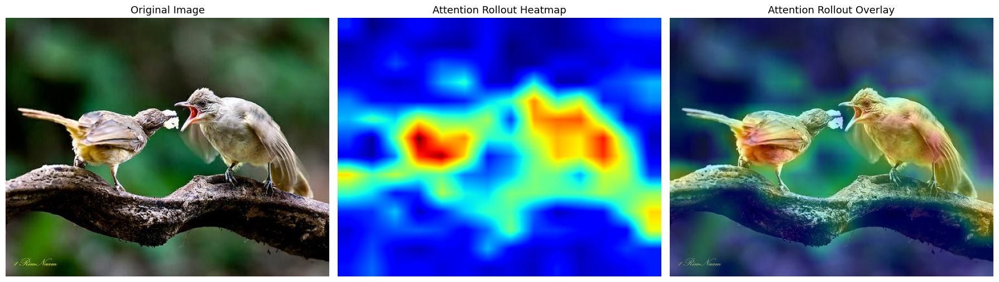


ATTENTION ROLLOUT: IMAGE 15
Predicted Class: indigo bunting, indigo finch, indigo bird, Passerina cyanea
Confidence: 0.9907


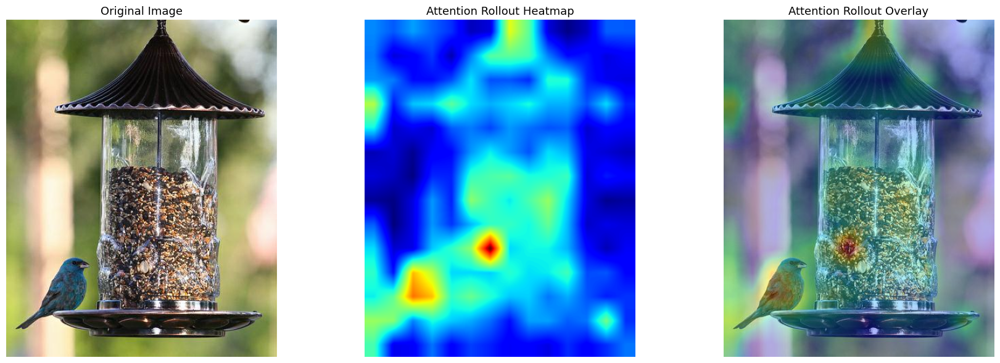


ATTENTION ROLLOUT: IMAGE 12
Predicted Class: junco, snowbird
Confidence: 0.9833


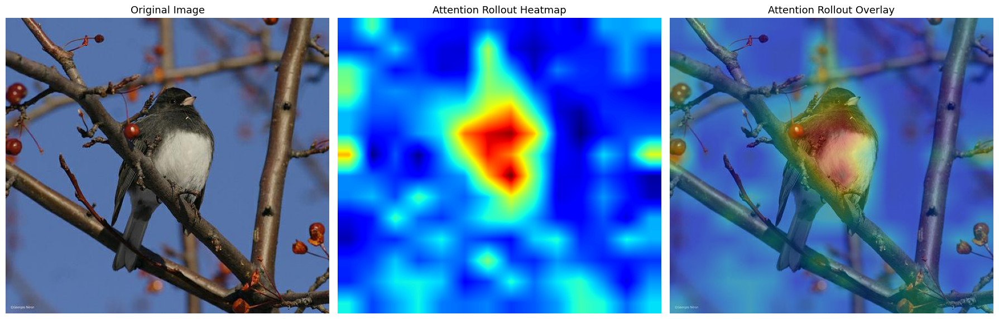


ATTENTION ROLLOUT: IMAGE 30
Predicted Class: jay
Confidence: 0.9807


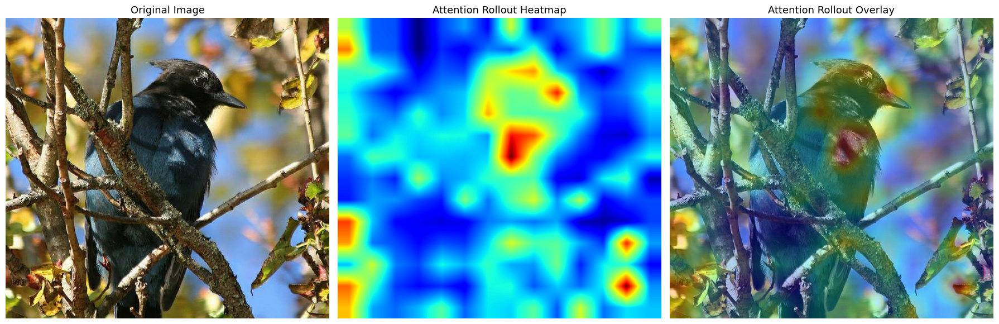

In [41]:
for selected_idx in SELECTED_INDICES:
  if selected_idx < 0 or selected_idx >= len(results):
    continue
  result = results[selected_idx]
  print("\n" + "=" * 70)
  print(f"ATTENTION ROLLOUT: IMAGE {selected_idx}")
  print("=" * 70)

# Load original image
  original_image = Image.open(
result["image_path"]
).convert("RGB")
# NEW: the original image is preprocessed again and .unsqueeze(0) adds the batch dimension, turning (3, 224, 224) into (1, 3, 224, 224) as the model expects.
  image_tensor = transform(
original_image
).unsqueeze(0).to(device)
# Extract attention maps
  attentions = get_attention_maps(
model,
image_tensor
)
# calls the rollout function from Activity 10 on the 12 attention tensors to get one 224x224 map.
  rollout_map = attention_rollout(
attentions,
discard_ratio=0.0
)
  print(f"Predicted Class: {result['pred_label']}")
  print(f"Confidence: {result['confidence']:.4f}")
# Visualize
  visualize_attention_rollout(
original_image,
rollout_map
)

Alpha value 0.7:


DATASET INDEX: 4
Image file: 7374881593269804.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00015/7374881593269804.jpg
Folder name (GT): 00015
Dataset label index: 4

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 15
Predicted label: robin, American robin, Turdus migratorius
Confidence: 0.9985

TOP-5 PREDICTIONS
--------------------------------------------------
1. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.9985)
2. worm fence, snake fence, snake-rail fence, Virginia fence (Class index: 912, Confidence: 0.0002)
3. grey fox, gray fox, Urocyon cinereoargenteus (Class index: 280, Confidence: 0.0002)
4. house finch, linnet, Carpodacus mexicanus (Class index: 12, Confidence: 0.0001)
5. brambling, Fringilla montifringilla (Class index: 10, Confidence: 0.0001)


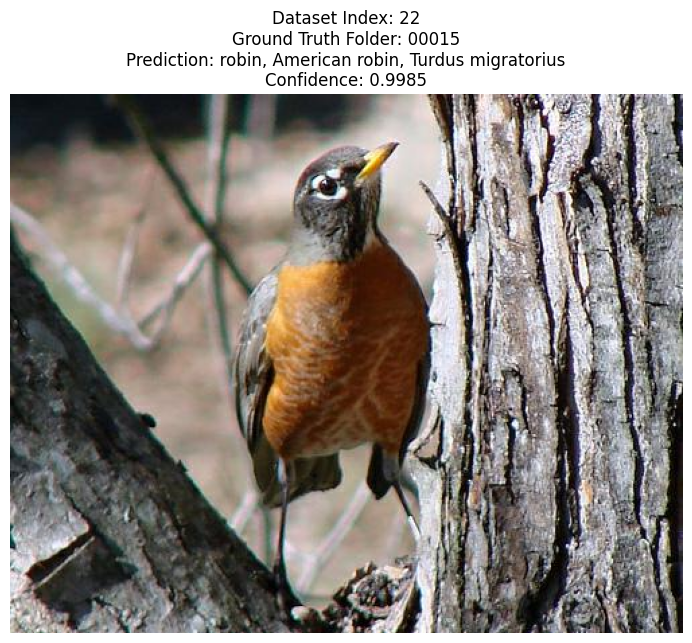


DATASET INDEX: 5
Image file: 3294314705554.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00016/3294314705554.jpg
Folder name (GT): 00016
Dataset label index: 5

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 16
Predicted label: bulbul
Confidence: 0.9920

TOP-5 PREDICTIONS
--------------------------------------------------
1. bulbul (Class index: 16, Confidence: 0.9920)
2. jay (Class index: 17, Confidence: 0.0014)
3. house finch, linnet, Carpodacus mexicanus (Class index: 12, Confidence: 0.0009)
4. bee eater (Class index: 92, Confidence: 0.0007)
5. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.0006)


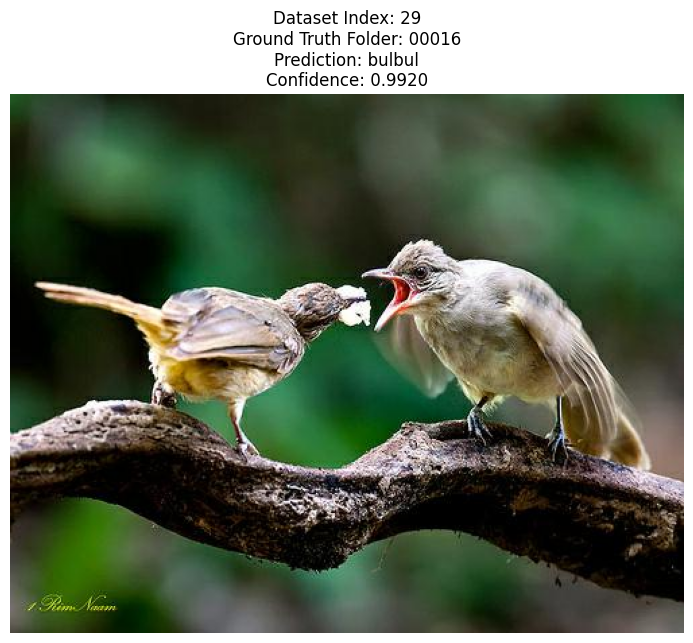


DATASET INDEX: 2
Image file: 606843467581765.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00013/606843467581765.jpg
Folder name (GT): 00013
Dataset label index: 2

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 13
Predicted label: junco, snowbird
Confidence: 0.9833

TOP-5 PREDICTIONS
--------------------------------------------------
1. junco, snowbird (Class index: 13, Confidence: 0.9833)
2. robin, American robin, Turdus migratorius (Class index: 15, Confidence: 0.0112)
3. chickadee (Class index: 19, Confidence: 0.0007)
4. magpie (Class index: 18, Confidence: 0.0007)
5. jay (Class index: 17, Confidence: 0.0007)


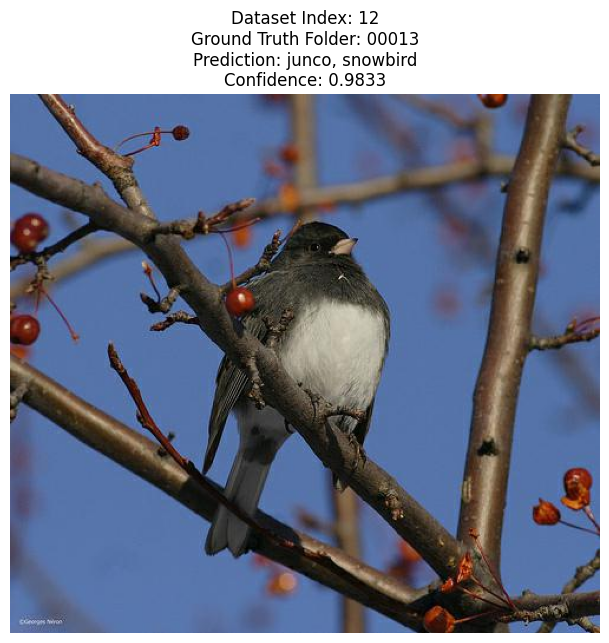


DATASET INDEX: 11
Image file: 3471677910505016.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00146/3471677910505016.jpg
Folder name (GT): 00146
Dataset label index: 11

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 146
Predicted label: albatross, mollymawk
Confidence: 0.9994

TOP-5 PREDICTIONS
--------------------------------------------------
1. albatross, mollymawk (Class index: 146, Confidence: 0.9994)
2. goose (Class index: 99, Confidence: 0.0001)
3. drake (Class index: 97, Confidence: 0.0001)
4. pelican (Class index: 144, Confidence: 0.0000)
5. oystercatcher, oyster catcher (Class index: 143, Confidence: 0.0000)


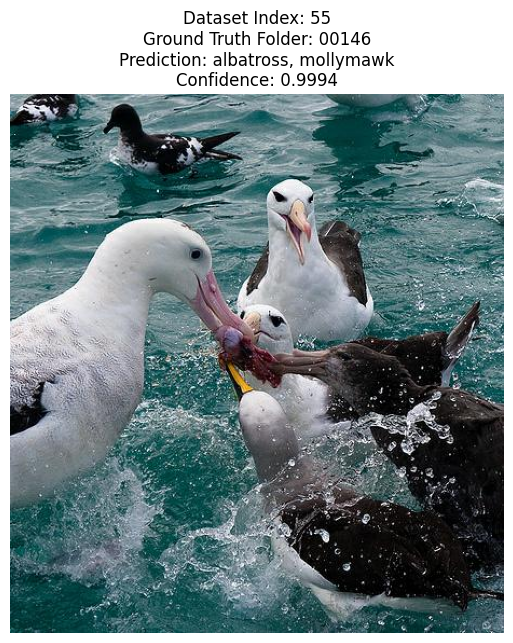

In [43]:
# a list of dataset positions that we inspect in detail; the same list is reused forb the attention rollout later.
SELECTED_INDICES = [22, 29, 12, 55]
# Display selected predictions with original images
for selected_idx in SELECTED_INDICES:
 if selected_idx < 0 or selected_idx >= len(results):
  print(f"Invalid dataset index: {selected_idx}")
  continue
 result = results[selected_idx]
 print("\n" + "=" * 75)

 print(f"DATASET INDEX: {result['dataset_index']}")
 print("=" * 75)
 print(f"Image file: {result['file_name']}")
 print(f"Full path: {result['image_path']}")
 print(f"Folder name (GT): {result['folder_name']}")
 print(f"Dataset label index: {result['true_label_idx']}")

 print("\nTOP-1 PREDICTION")
 print("-" * 50)

 print(f"Predicted ImageNet class index: {result['pred_class_idx']}")
 print(f"Predicted label: {result['pred_label']}")
 print(f"Confidence: {result['confidence']:.4f}")

 print("\nTOP-5 PREDICTIONS")
 print("-" * 50)
 for prediction in result["top5"]:
  print(
f"{prediction['rank']}. "
f"{prediction['label']} "
f"(Class index: {prediction['class_index']}, "
f"Confidence: {prediction['confidence']:.4f})"
)
# PIL.Image.open loads the original full-size image (before the 224x224 resizing) so it can be displayed clearly.
 img = Image.open(result["image_path"]).convert("RGB")
# Display image alongside prediction information
 plt.figure(figsize=(13, 7))
 plt.imshow(img)
 plt.title(
f"Dataset Index: {selected_idx}\n"
f"Ground Truth Folder: {result['folder_name']}\n"
f"Prediction: {result['pred_label']}\n"
f"Confidence: {result['confidence']:.4f}",
fontsize=12
)
 plt.axis("off")
 plt.show()

In [44]:
# Extract Attention Maps
def get_attention_maps(model, image_tensor):
 with torch.no_grad():
# output_attentions=True makes the model return its self-attention matrices.
  outputs = model(
pixel_values=image_tensor,
output_attentions=True
)
# attentions is a tuple of 12 tensors (one per encoder block). Each has shape (1,12, 197, 197) = (batch, heads, tokens, tokens). Entry [i, j] says how much token i
#attends to token j.
 return outputs.attentions

In [45]:
def attention_rollout(attentions, discard_ratio=0.0):
 num_tokens = attentions[0].shape[-1]
# Attention Rollout starts from the identity matrix and multiplies the attention of
#each layer onto it. This traces how information flows from the input patches to the final layer.
 result = torch.eye(
 num_tokens,
device=attentions[0].device
)
 for attention in attentions:
# Remove batch dimension
  attention = attention.squeeze(0)
# averages the 12 heads into a single 197x197 attention matrix.
  fused = attention.mean(dim=0)
# optional step that sets the weakest attention values to zero to reduce noise. It is off here (discard_ratio=0.0).
  if discard_ratio > 0:
    flat = fused.flatten()
    num_discard = int(
flat.numel() * discard_ratio
)
    if num_discard > 0:
     indices = torch.argsort(flat)[:num_discard]
     flat[indices] = 0

# adding the identity matrix models the residual (skip) connections of the transformer, which pass the original token forward along with the attention output.
  fused = fused + torch.eye(
   num_tokens,
device=fused.device
)
# each row is re-normalised to sum to 1 so it stays a valid attention distribution.
  fused = fused / fused.sum(
dim=-1,
keepdim=True
)
# matrix multiplication (@) chains the layers together, so the final matrix describes attention across the whole network.
  result = fused @ result
# row 0 is the [CLS] token. Taking columns 1 onward gives the importance of the 196 image patches for the classification.
  mask = result[0, 1:]
# the 196 patch values are arranged back into a 14x14 grid matching the patch positions in the image.
  mask = mask.reshape(14, 14)
#bilinear upsampling enlarges the 14x14 grid to 224x224 so it looks like a smooth heatmap.
  mask = F.interpolate(
  mask.unsqueeze(0).unsqueeze(0),
size=(224, 224),
mode="bilinear",
align_corners=False
).squeeze()
 mask = mask.cpu().numpy()
# min-max normalisation scales the map to the range 0 to 1 (1e-8 prevents division by zero).
 mask = (
(mask - mask.min()) /
(mask.max() - mask.min() + 1e-8)
)
 return mask

In [46]:
def visualize_attention_rollout(original_image, rollout_map):
# Get original image dimensions
  width, height = original_image.size
# cv2.resize stretches the attention map to the original image width and height so that the overlay is aligned.
  rollout_resized = cv2.resize(
rollout_map,
(width, height),
interpolation=cv2.INTER_CUBIC
)
# np.clip keeps every value inside 0 to 1 (bicubic resizing can overshoot slightly).
  rollout_resized = np.clip(rollout_resized, 0, 1)

# Create visualization
  fig, axes = plt.subplots(
1, 3,
figsize=(18, 6)
)
# 1. Original image
  axes[0].imshow(original_image)
  axes[0].set_title("Original Image", fontsize=13)
  axes[0].axis("off")
# 2. Attention rollout heatmap
  axes[1].imshow(
rollout_resized,
cmap="jet",
vmin=0,
vmax=1,
interpolation="bilinear"
)
  axes[1].set_title(
"Attention Rollout Heatmap",
fontsize=13
)
  axes[1].axis("off")
# 3. Correctly aligned attention overlay
  axes[2].imshow(original_image)
  axes[2].imshow(
rollout_resized,
cmap="jet",
# alpha sets the transparency of the heatmap (0.7) so the original image stays visible underneath.
alpha=0.7,
vmin=0,
vmax=1,
interpolation="bilinear"
)
  axes[2].set_title(
"Attention Rollout Overlay",
fontsize=13
)
  axes[2].axis("off")
  plt.tight_layout()
  plt.show()


ATTENTION ROLLOUT: IMAGE 22
Predicted Class: robin, American robin, Turdus migratorius
Confidence: 0.9985


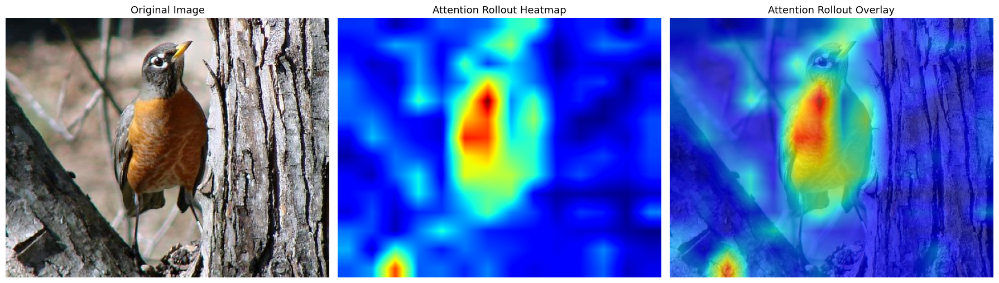


ATTENTION ROLLOUT: IMAGE 29
Predicted Class: bulbul
Confidence: 0.9920


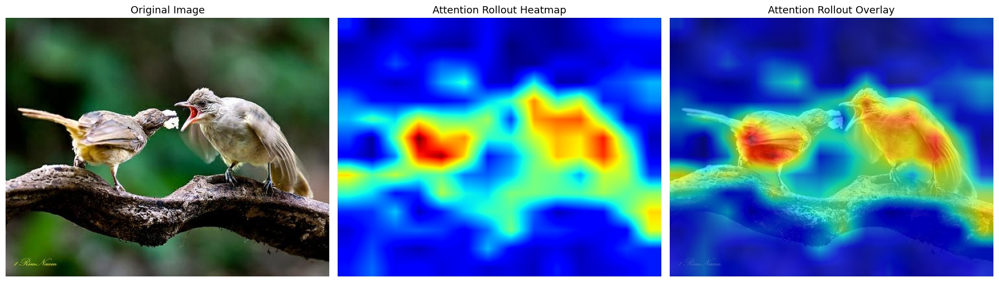


ATTENTION ROLLOUT: IMAGE 12
Predicted Class: junco, snowbird
Confidence: 0.9833


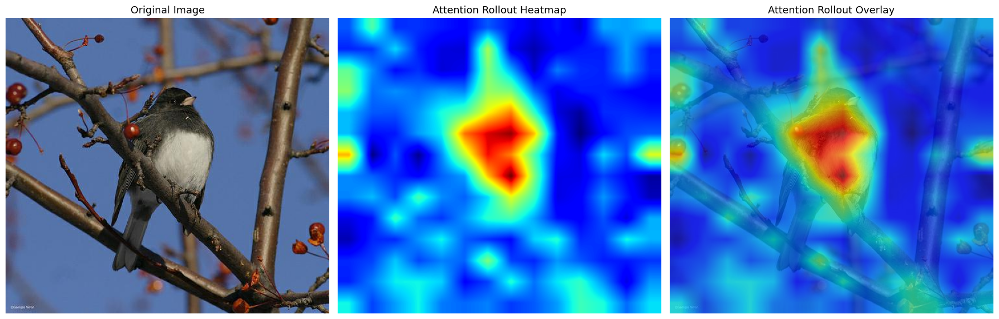


ATTENTION ROLLOUT: IMAGE 55
Predicted Class: albatross, mollymawk
Confidence: 0.9994


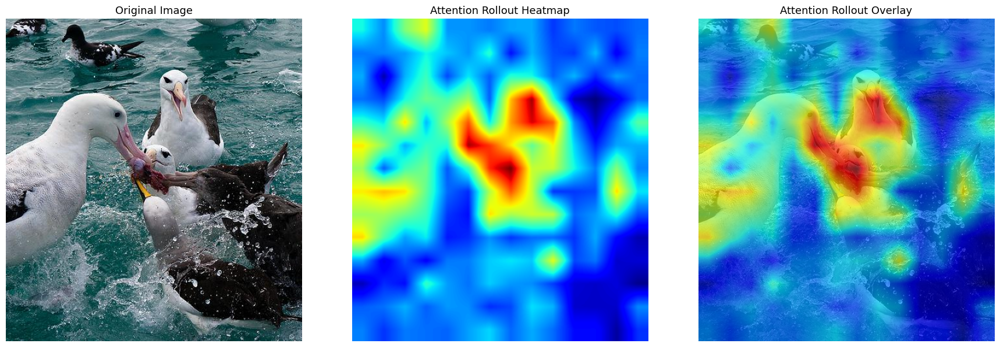

In [47]:
for selected_idx in SELECTED_INDICES:
  if selected_idx < 0 or selected_idx >= len(results):
    continue
  result = results[selected_idx]
  print("\n" + "=" * 70)
  print(f"ATTENTION ROLLOUT: IMAGE {selected_idx}")
  print("=" * 70)

# Load original image
  original_image = Image.open(
result["image_path"]
).convert("RGB")
# NEW: the original image is preprocessed again and .unsqueeze(0) adds the batch dimension, turning (3, 224, 224) into (1, 3, 224, 224) as the model expects.
  image_tensor = transform(
original_image
).unsqueeze(0).to(device)
# Extract attention maps
  attentions = get_attention_maps(
model,
image_tensor
)
# calls the rollout function from Activity 10 on the 12 attention tensors to get one 224x224 map.
  rollout_map = attention_rollout(
attentions,
discard_ratio=0.0
)
  print(f"Predicted Class: {result['pred_label']}")
  print(f"Confidence: {result['confidence']:.4f}")
# Visualize
  visualize_attention_rollout(
original_image,
rollout_map
)